# Pipeline Step 3 — VAE Architecture, Latent-Dimension Sweep and Training
**GWU Praxis, Chapter 3 (Section 3.5 and 3.8)**

Trains one Variational Autoencoder per dataset on the **known-class training split only**; the held-out class is never loaded.

1. **Sweep** d_z ∈ {8, 16, 32, 64} on a training subsample and pick the smallest d_z whose validation reconstruction loss is within 5% of the best (Section 3.8).
2. **Train** the final VAE at that d_z on the full training split: Adam (lr 1e-3), batch 256, up to 150 epochs, β annealed 0 → 1 over 50 epochs, early stopping after 15 epochs without improvement in validation ELBO (Section 3.5.3).
3. **Check** for posterior collapse by counting active latent units.

**Requires:** Steps 1–2. **Produces** (in `outputs_praxis_heldout/VAETrain/`): `*_vae_final.weights.h5`, `*_vae_config.pkl`, `latent_dim_sweep.csv`, `collapse_diagnostic.csv`, training curves.

## 0 · Imports and settings

In [1]:
# ────────────────────────────────────────────────────────────────────────────
# IMPORTS, SEED AND SESSION SETUP
# PRAXIS_BASE (environment variable) lets the notebook run outside Colab.
# ────────────────────────────────────────────────────────────────────────────
import os, pickle, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
keras.utils.set_random_seed(RANDOM_SEED)       # Python, NumPy and TensorFlow together

# Set this to your project folder in Google Drive (it must end with "/").
BASE = os.environ.get("PRAXIS_BASE", "/content/drive/MyDrive/<YOUR_PROJECT_FOLDER>/")
RUN_DIR = "outputs_praxis_heldout"   # results folder
if "PRAXIS_BASE" not in os.environ:
    from google.colab import drive
    drive.mount("/content/drive")
PIPE = Path(BASE) / RUN_DIR / "pipeline"
OUT = Path(BASE) / RUN_DIR / "VAETrain"
OUT.mkdir(parents=True, exist_ok=True)
DATASETS = ["CIC-IDS2017", "UNSW-NB15", "NSL-KDD"]
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Mounted at /content/drive
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ────────────────────────────────────────────────────────────────────────────
# TRAINING SETTINGS (Section 3.5.3 and 3.8)
#
# LR, BATCH, MAX_EPOCHS, PATIENCE and ANNEAL_EPOCHS follow Section 3.5.3.
# The sweep uses a stratified training subsample and a shorter epoch cap to
# keep run time reasonable; the final model uses the full training split.
# RETRAIN=False reuses a finished VAE if its weights already exist, so the
# notebook can be resumed after a Colab disconnect.
# ────────────────────────────────────────────────────────────────────────────
LR            = 1e-3
BATCH         = 256
MAX_EPOCHS    = 150
PATIENCE      = 15      # epochs without improvement in validation ELBO (counted after annealing)
ANNEAL_EPOCHS = 50      # β rises linearly from 0 to 1 over these epochs

DZ_GRID          = [8, 16, 32, 64]
SWEEP_TOLERANCE  = 0.05     # smallest d_z within 5% of the best validation reconstruction loss
SWEEP_TRAIN_ROWS = 200_000
SWEEP_VAL_ROWS   = 50_000
SWEEP_MAX_EPOCHS = 80

RETRAIN = False

# Section 3.6.3 retraining rule. If Step 4 reports a round-1 acceptance rate
# below 85% for a dataset (it writes retrain_flags.json), add the dataset here and
# rerun Steps 3 and 4: that dataset's VAE is retrained at the same d_z with
# ANNEAL_EXTRA more KL-annealing epochs. Other datasets are reused from disk.
RETRAIN_RULE_DATASETS = []
ANNEAL_EXTRA = 25


## 1 · Load preprocessed data
Only the training and validation splits are loaded; the test and held-out sets are not needed here.

In [3]:
# ────────────────────────────────────────────────────────────────────────────
# LOAD TRAIN AND VALIDATION SPLITS
# Feature columns come from the Step 2 metadata so every step uses the same
# columns in the same order.
# ────────────────────────────────────────────────────────────────────────────
splits = {}
for name in DATASETS:
    meta = pickle.load(open(PIPE / f"{name}_preprocess.pkl", "rb"))
    fc, lab = meta["feat_cols"], meta["label_col"]
    train = pd.read_csv(PIPE / f"{name}_train.csv")
    val = pd.read_csv(PIPE / f"{name}_val.csv")
    assert not train[lab].isin(meta["holdout"]).any(), "held-out class found in training data"
    splits[name] = dict(X_train=train[fc].to_numpy(np.float32), y_train=train[lab].to_numpy(),
                        X_val=val[fc].to_numpy(np.float32), feat_cols=fc, label_col=lab)
    print(f"{name}: train {len(train):,} × {len(fc)} features | val {len(val):,}")

CIC-IDS2017: train 1,765,639 × 45 features | val 365,515
UNSW-NB15: train 112,901 × 49 features | val 22,531
NSL-KDD: train 103,464 × 92 features | val 21,939


## 2 · VAE architecture (Section 3.5.2)
- Encoder: input → 256 → 128 → 64 (Dense + BatchNorm + ReLU) → μ and log σ² heads of size d_z
- Decoder: d_z → 64 → 128 → 256 → input (sigmoid output, matching the [0, 1] inputs)
- Loss: binary cross-entropy reconstruction + β · KL divergence (the negative ELBO)

In [4]:
# ────────────────────────────────────────────────────────────────────────────
# ENCODER, DECODER AND VAE MODEL
#
# Sampling implements the reparameterization trick z = μ + ε·σ (Eq. 3.1).
# The VAE reports total loss (negative ELBO at the current β), reconstruction
# loss and KL divergence separately, so each can be monitored.
# ────────────────────────────────────────────────────────────────────────────
def build_encoder(input_dim, latent_dim):
    inp = keras.Input(shape=(input_dim,), name="encoder_input")
    x = inp
    for i, units in enumerate([256, 128, 64], 1):
        x = layers.Dense(units, name=f"enc_d{i}")(x)
        x = layers.BatchNormalization(name=f"enc_bn{i}")(x)
        x = layers.ReLU(name=f"enc_r{i}")(x)
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    return keras.Model(inp, [z_mean, z_log_var], name="encoder")


def build_decoder(latent_dim, output_dim):
    inp = keras.Input(shape=(latent_dim,), name="decoder_input")
    x = inp
    for i, units in enumerate([64, 128, 256], 1):
        x = layers.Dense(units, name=f"dec_d{i}")(x)
        x = layers.BatchNormalization(name=f"dec_bn{i}")(x)
        x = layers.ReLU(name=f"dec_r{i}")(x)
    out = layers.Dense(output_dim, activation="sigmoid", name="dec_output")(x)
    return keras.Model(inp, out, name="decoder")


class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        eps = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * eps


class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder, self.sampling = encoder, decoder, Sampling()
        self.beta = tf.Variable(0.0, trainable=False, dtype=tf.float32)
        self.total_tracker = keras.metrics.Mean(name="loss")
        self.recon_tracker = keras.metrics.Mean(name="recon_loss")
        self.kl_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_tracker, self.recon_tracker, self.kl_tracker]

    def call(self, inputs, training=False):
        z_mean, z_log_var = self.encoder(inputs, training=training)
        z = self.sampling([z_mean, z_log_var])
        return self.decoder(z, training=training), z_mean, z_log_var

    def _vae_losses(self, x, training):
        recon, z_mean, z_log_var = self(x, training=training)
        # BCE summed over features, averaged over the batch
        recon_loss = tf.reduce_mean(tf.reduce_sum(
            keras.losses.binary_crossentropy(x[..., None], recon[..., None]), axis=-1))
        kl = -0.5 * tf.reduce_mean(tf.reduce_sum(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1))
        return recon_loss + self.beta * kl, recon_loss, kl

    def _record(self, total, recon, kl):
        self.total_tracker.update_state(total)
        self.recon_tracker.update_state(recon)
        self.kl_tracker.update_state(kl)
        return {m.name: m.result() for m in self.metrics}

    def train_step(self, data):
        x = data[0] if isinstance(data, tuple) else data
        with tf.GradientTape() as tape:
            total, recon, kl = self._vae_losses(x, training=True)
        grads = tape.gradient(total, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        return self._record(total, recon, kl)

    def test_step(self, data):
        x = data[0] if isinstance(data, tuple) else data
        return self._record(*self._vae_losses(x, training=False))


def make_vae(input_dim, latent_dim):
    vae = VAE(build_encoder(input_dim, latent_dim), build_decoder(latent_dim, input_dim))
    vae.compile(optimizer=keras.optimizers.Adam(learning_rate=LR, beta_1=0.9, beta_2=0.999))
    vae(np.zeros((1, input_dim), np.float32))           # build weights
    return vae

print("VAE defined")

VAE defined


## 3 · KL annealing and early stopping
Validation ELBO is only comparable between epochs once β has reached 1, so the best model is tracked, and patience counted, from the end of annealing onward. Keras' built-in `EarlyStopping`/`ModelCheckpoint` would otherwise keep an early epoch where β≈0 and the loss is artificially low.

In [5]:
# ────────────────────────────────────────────────────────────────────────────
# CALLBACKS
#
# KLAnnealing: β_t = min(1, t / ANNEAL_EPOCHS) at the start of each epoch (Eq. 3.2).
# BestAfterAnneal: from the first epoch with β = 1, keeps the weights with the
# lowest validation loss (= negative ELBO), stops after `patience` epochs
# without improvement, and restores the best weights when training ends.
# ────────────────────────────────────────────────────────────────────────────
class KLAnnealing(keras.callbacks.Callback):
    def __init__(self, anneal_epochs):
        super().__init__()
        self.anneal_epochs = anneal_epochs

    def on_epoch_begin(self, epoch, logs=None):
        self.model.beta.assign(float(min(1.0, epoch / max(self.anneal_epochs, 1))))

    def on_epoch_end(self, epoch, logs=None):
        if logs is not None:
            logs["beta"] = float(self.model.beta.numpy())


class BestAfterAnneal(keras.callbacks.Callback):
    def __init__(self, anneal_epochs, patience):
        super().__init__()
        self.anneal_epochs, self.patience = anneal_epochs, patience
        self.best, self.best_weights, self.best_epoch, self.wait = np.inf, None, None, 0

    def on_epoch_end(self, epoch, logs=None):
        if epoch < self.anneal_epochs:           # β < 1: losses not comparable yet
            return
        current = logs["val_loss"]
        if current < self.best:
            self.best, self.best_epoch, self.wait = current, epoch, 0
            self.best_weights = self.model.get_weights()
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)


def fit_vae(X_train, X_val, latent_dim, max_epochs, log_path=None, anneal=ANNEAL_EPOCHS):
    """Train one VAE and return (model, history, best_epoch, best_val_loss)."""
    vae = make_vae(X_train.shape[1], latent_dim)
    best = BestAfterAnneal(anneal, PATIENCE)
    cbs = [KLAnnealing(anneal), best]
    if log_path:
        cbs.append(keras.callbacks.CSVLogger(str(log_path)))
    hist = vae.fit(X_train, X_train, validation_data=(X_val, X_val), epochs=max_epochs,
                   batch_size=BATCH, callbacks=cbs, verbose=2)
    return vae, hist, best.best_epoch, best.best


def val_recon_loss(vae, X, batch=8192):
    """Mean per-record BCE reconstruction loss using the posterior mean (no sampling noise)."""
    mu, _ = vae.encoder.predict(X, batch_size=batch, verbose=0)
    recon = vae.decoder.predict(mu, batch_size=batch, verbose=0)
    eps = 1e-7
    r = np.clip(recon, eps, 1 - eps)
    return float(np.mean(-np.sum(X * np.log(r) + (1 - X) * np.log(1 - r), axis=1)))

## 4 · Latent-dimension sweep (Section 3.8)
For each dataset and each d_z, a VAE is trained on a stratified subsample of the training split and scored on a validation subsample. The selected d_z is the **smallest** value whose validation reconstruction loss is within 5% of the best.

In [6]:
# ────────────────────────────────────────────────────────────────────────────
# RUN THE SWEEP
#
# Results are saved after every run, so a disconnect loses at most one run.
# If latent_dim_sweep.csv already holds a result for a (dataset, d_z) pair,
# that run is skipped.
# ────────────────────────────────────────────────────────────────────────────
def stratified_rows(y, n, seed=RANDOM_SEED):
    """Row indices for a sample of about n rows that keeps every class represented."""
    if len(y) <= n:
        return np.arange(len(y))
    rng = np.random.default_rng(seed)
    idx = []
    for cls in np.unique(y):
        rows = np.flatnonzero(y == cls)
        k = max(min(len(rows), 50), int(round(n * len(rows) / len(y))))
        idx.append(rng.choice(rows, size=min(k, len(rows)), replace=False))
    return np.sort(np.concatenate(idx))

sweep_path = OUT / "latent_dim_sweep.csv"
sweep = pd.read_csv(sweep_path) if sweep_path.exists() and not RETRAIN else pd.DataFrame(
    columns=["dataset", "latent_dim", "val_recon_loss", "best_epoch", "epochs_run"])

for name in DATASETS:
    s = splits[name]
    tr = stratified_rows(s["y_train"], SWEEP_TRAIN_ROWS)
    rng = np.random.default_rng(RANDOM_SEED)
    va = rng.choice(len(s["X_val"]), size=min(SWEEP_VAL_ROWS, len(s["X_val"])), replace=False)
    for dz in DZ_GRID:
        if ((sweep["dataset"] == name) & (sweep["latent_dim"] == dz)).any():
            continue
        print(f"\n── sweep {name}  d_z={dz} ──")
        keras.utils.set_random_seed(RANDOM_SEED)
        vae, hist, best_ep, _ = fit_vae(s["X_train"][tr], s["X_val"][va], dz, SWEEP_MAX_EPOCHS)
        row = dict(dataset=name, latent_dim=dz, val_recon_loss=val_recon_loss(vae, s["X_val"][va]),
                   best_epoch=best_ep, epochs_run=len(hist.history["loss"]))
        sweep = pd.concat([sweep, pd.DataFrame([row])], ignore_index=True)
        sweep.to_csv(sweep_path, index=False)
        keras.backend.clear_session()


── sweep CIC-IDS2017  d_z=8 ──
Epoch 1/80
782/782 - 20s - 26ms/step - kl_loss: 31.2545 - loss: 3.7855 - recon_loss: 3.7855 - val_kl_loss: 38.6251 - val_loss: 3.0591 - val_recon_loss: 3.0591 - beta: 0.0000e+00
Epoch 2/80
782/782 - 3s - 4ms/step - kl_loss: 9.0374 - loss: 3.2222 - recon_loss: 3.0414 - val_kl_loss: 8.2183 - val_loss: 3.2474 - val_recon_loss: 3.0830 - beta: 0.0200
Epoch 3/80
782/782 - 4s - 4ms/step - kl_loss: 6.5133 - loss: 3.3126 - recon_loss: 3.0521 - val_kl_loss: 6.3498 - val_loss: 3.3529 - val_recon_loss: 3.0989 - beta: 0.0400
Epoch 4/80
782/782 - 4s - 4ms/step - kl_loss: 5.5592 - loss: 3.4016 - recon_loss: 3.0680 - val_kl_loss: 5.6000 - val_loss: 3.4577 - val_recon_loss: 3.1217 - beta: 0.0600
Epoch 5/80
782/782 - 4s - 5ms/step - kl_loss: 4.9893 - loss: 3.4840 - recon_loss: 3.0848 - val_kl_loss: 5.1344 - val_loss: 3.5371 - val_recon_loss: 3.1263 - beta: 0.0800
Epoch 6/80
782/782 - 3s - 4ms/step - kl_loss: 4.6039 - loss: 3.5627 - recon_loss: 3.1023 - val_kl_loss: 4.6215


── sweep CIC-IDS2017  d_z=32 ──
Epoch 1/80
782/782 - 16s - 20ms/step - kl_loss: 65.6512 - loss: 3.7790 - recon_loss: 3.7790 - val_kl_loss: 90.8814 - val_loss: 3.0493 - val_recon_loss: 3.0493 - beta: 0.0000e+00
Epoch 2/80
782/782 - 3s - 4ms/step - kl_loss: 12.2617 - loss: 3.3323 - recon_loss: 3.0871 - val_kl_loss: 9.7099 - val_loss: 3.3000 - val_recon_loss: 3.1058 - beta: 0.0200
Epoch 3/80
782/782 - 3s - 4ms/step - kl_loss: 7.2048 - loss: 3.3663 - recon_loss: 3.0782 - val_kl_loss: 6.9513 - val_loss: 3.3867 - val_recon_loss: 3.1087 - beta: 0.0400
Epoch 4/80
782/782 - 3s - 4ms/step - kl_loss: 5.8923 - loss: 3.4373 - recon_loss: 3.0837 - val_kl_loss: 6.1653 - val_loss: 3.4998 - val_recon_loss: 3.1298 - beta: 0.0600
Epoch 5/80
782/782 - 3s - 4ms/step - kl_loss: 5.2330 - loss: 3.5144 - recon_loss: 3.0957 - val_kl_loss: 5.1709 - val_loss: 3.5641 - val_recon_loss: 3.1505 - beta: 0.0800
Epoch 6/80
782/782 - 3s - 4ms/step - kl_loss: 4.7949 - loss: 3.5905 - recon_loss: 3.1110 - val_kl_loss: 4.93

In [7]:
# ────────────────────────────────────────────────────────────────────────────
# SELECT d_z PER DATASET
# Smallest d_z with validation reconstruction loss ≤ (1 + SWEEP_TOLERANCE) × best.
# ────────────────────────────────────────────────────────────────────────────
LATENT_DIM = {}
for name in DATASETS:
    sw = sweep[sweep["dataset"] == name].sort_values("latent_dim")
    best = sw["val_recon_loss"].min()
    ok = sw[sw["val_recon_loss"] <= (1 + SWEEP_TOLERANCE) * best]
    LATENT_DIM[name] = int(ok["latent_dim"].min())
    sweep.loc[sweep["dataset"] == name, "selected"] = sweep.loc[sweep["dataset"] == name, "latent_dim"] == LATENT_DIM[name]
sweep.to_csv(sweep_path, index=False)
display(sweep)
print("Selected d_z:", LATENT_DIM)

,dataset,latent_dim,val_recon_loss,best_epoch,epochs_run,selected
0,CIC-IDS2017,8,3.549714,69,80,True
1,CIC-IDS2017,16,3.571056,79,80,False
2,CIC-IDS2017,32,3.538974,73,80,False
3,CIC-IDS2017,64,3.563049,77,80,False
4,UNSW-NB15,8,4.079725,74,80,True
5,UNSW-NB15,16,4.077122,79,80,False
6,UNSW-NB15,32,4.120869,78,80,False
7,UNSW-NB15,64,4.090641,75,80,False
8,NSL-KDD,8,2.313033,79,80,True
9,NSL-KDD,16,2.244453,77,80,False


Selected d_z: {'CIC-IDS2017': 8, 'UNSW-NB15': 8, 'NSL-KDD': 8}


## 5 · Train the final VAE per dataset
Full training split, selected d_z. The weights at the lowest post-annealing validation ELBO are saved.

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# FINAL TRAINING
#
# Skipped for a dataset whose final weights and config already exist (unless
# RETRAIN=True) and whose saved d_z matches the sweep's choice.
# ────────────────────────────────────────────────────────────────────────────
vaes, histories = {}, {}
for name in DATASETS:
    s, dz = splits[name], LATENT_DIM[name]
    anneal = ANNEAL_EPOCHS + (ANNEAL_EXTRA if name in RETRAIN_RULE_DATASETS else 0)
    w_path, c_path = OUT / f"{name}_vae_final.weights.h5", OUT / f"{name}_vae_config.pkl"
    if not RETRAIN and w_path.exists() and c_path.exists() \
            and pickle.load(open(c_path, "rb"))["latent_dim"] == dz \
            and pickle.load(open(c_path, "rb")).get("anneal_epochs") == anneal:
        vae = make_vae(len(s["feat_cols"]), dz)
        vae.load_weights(w_path)
        vaes[name] = vae
        print(f"{name}: reusing saved VAE (d_z={dz})")
        continue
    print(f"\n══ Training final VAE — {name} (d_z={dz}, annealing {anneal} epochs) ══")
    keras.utils.set_random_seed(RANDOM_SEED)
    vae, hist, best_ep, best_loss = fit_vae(s["X_train"], s["X_val"], dz, MAX_EPOCHS,
                                            log_path=OUT / f"{name}_vae_history.csv", anneal=anneal)
    assert best_ep is not None, f"{name}: training ended before annealing finished"
    vae.save_weights(w_path)
    pickle.dump(dict(latent_dim=dz, input_dim=len(s["feat_cols"]), feat_cols=s["feat_cols"],
                     best_epoch=int(best_ep) + 1, best_val_neg_elbo=float(best_loss),
                     lr=LR, batch=BATCH, anneal_epochs=anneal, patience=PATIENCE,
                     retraining_rule_applied=name in RETRAIN_RULE_DATASETS),
                open(c_path, "wb"))
    vaes[name], histories[name] = vae, hist.history
    print(f"  best epoch {best_ep + 1}, validation negative ELBO {best_loss:.4f}")


══ Training final VAE — CIC-IDS2017 (d_z=8, annealing 50 epochs) ══
Epoch 1/150


## 6 · Training curves

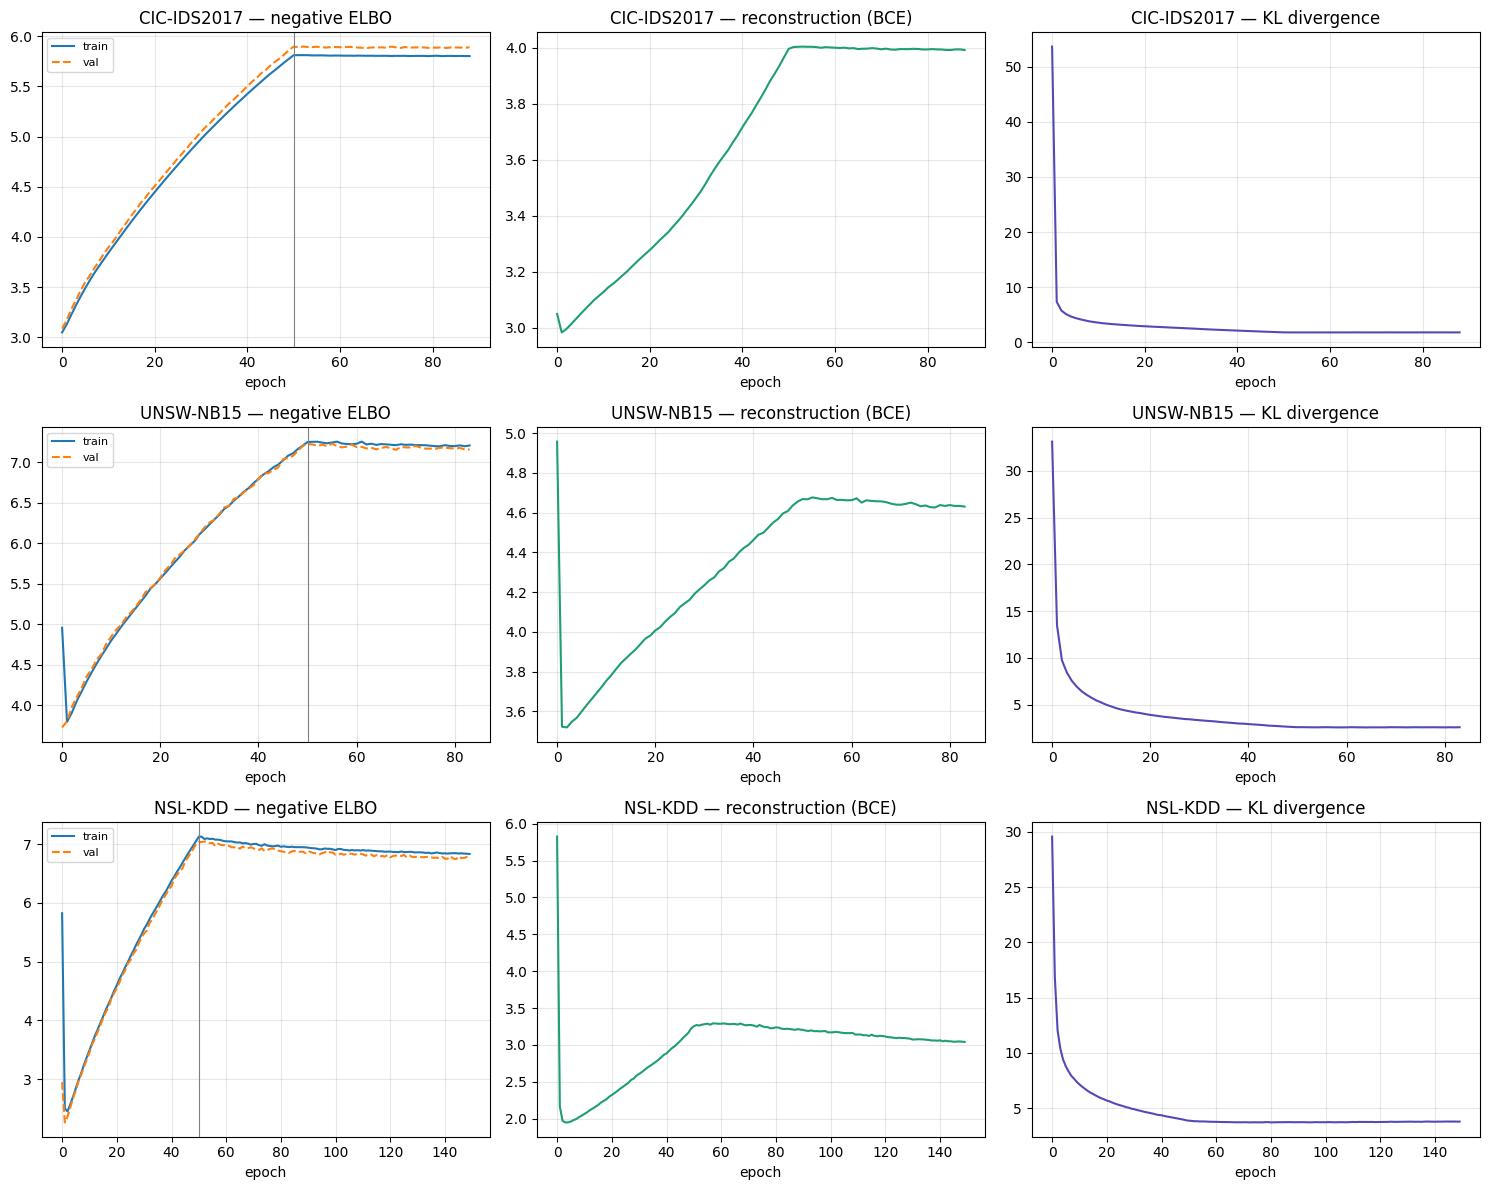

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# PLOT LOSS, RECONSTRUCTION AND KL PER EPOCH
# Read from the CSV log, so curves also appear for VAEs reused from disk.
# KL should rise and settle once β approaches 1; a KL near zero throughout
# signals posterior collapse.
# ────────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(len(DATASETS), 3, figsize=(15, 4 * len(DATASETS)), squeeze=False)
for i, name in enumerate(DATASETS):
    p = OUT / f"{name}_vae_history.csv"
    if not p.exists():
        continue
    h = pd.read_csv(p)
    axes[i, 0].plot(h["loss"], label="train"); axes[i, 0].plot(h["val_loss"], "--", label="val")
    axes[i, 0].axvline(ANNEAL_EPOCHS, color="grey", lw=0.8); axes[i, 0].legend(fontsize=8)
    axes[i, 1].plot(h["recon_loss"], color="#1D9E75")
    axes[i, 2].plot(h["kl_loss"], color="#534AB7")
    for ax, t in zip(axes[i], ["negative ELBO", "reconstruction (BCE)", "KL divergence"]):
        ax.set_title(f"{name} — {t}"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "vae_training_curves.png", dpi=120)
plt.show()

## 7 · Reconstruction quality and posterior-collapse diagnostic
A latent unit is **active** if the variance of its posterior mean μ across validation records exceeds 0.01. Collapse shows up as few or no active units: the encoder then returns nearly the same μ for every input. (The average posterior variance is close to 1 precisely when collapse occurs, so it cannot detect it.)

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# ACTIVE UNITS AND RECONSTRUCTION ERROR
# Uses up to 100,000 validation records, encoded in batches to limit memory.
# ────────────────────────────────────────────────────────────────────────────
rows = []
for name in DATASETS:
    X = splits[name]["X_val"]
    X = X[np.random.default_rng(RANDOM_SEED).choice(len(X), size=min(100_000, len(X)), replace=False)]
    mu, logvar = vaes[name].encoder.predict(X, batch_size=8192, verbose=0)
    recon = vaes[name].decoder.predict(mu, batch_size=8192, verbose=0)
    active = int((mu.var(axis=0) > 0.01).sum())
    rows.append(dict(dataset=name, latent_dim=LATENT_DIM[name], active_units=active,
                     val_mae=float(np.mean(np.abs(X - recon))),
                     val_bce=val_recon_loss(vaes[name], X),
                     status="collapsed" if active == 0 else ("partial" if active < LATENT_DIM[name] // 4 else "ok")))
diag = pd.DataFrame(rows)
diag.to_csv(OUT / "collapse_diagnostic.csv", index=False)
display(diag)
print("\n✓ VAEs ready — continue with Step 4")

,dataset,latent_dim,active_units,val_mae,val_bce,status
0,CIC-IDS2017,8,3,0.013827,3.510909,ok
1,UNSW-NB15,8,6,0.020768,4.126797,ok
2,NSL-KDD,8,5,0.007769,2.270174,ok



✓ VAEs ready — continue with Step 4
